In [118]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter

In [119]:
data = pd.read_csv("données/LucasBenjamin_66ca2d90ab22cf378a032c83.csv", skiprows=1, index_col=3)
data

,rt,url,trial_type,time_elapsed,internal_node_id,success,responses,view_history,trial_rt,response_rts,stimulus,presented_angles,stimulus_rotations,key_press,final_angle,confidence,target,score,correct
trial_index,,,,,,,,,,,,,,,,,,,
0,19613.0,external-consent.html,external-html,19743,0.0-0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,fullscreen,23200,0.0-1.0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,5437.0,NaN,survey-dropdown,28640,0.0-2.0,NaN,"{""0"":""18-25"",""1"":""F""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4421.0,NaN,survey-text,33063,0.0-3.0,NaN,"{""Q0"":""6777f3e9760d3844217b5ea8""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,20970.0,NaN,instructions,54033,0.0-4.0,NaN,NaN,"[{""page_index"":0,""viewing_time"":4385},{""page_i...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
296,NaN,NaN,lb-SeqAns-visual,2558325,0.0-224.0,NaN,NaN,NaN,1277.0,NaN,Stims/Gabor_img/Gabor_0.png,45.5073715096,0,NaN,34.530826,0.0,45.507372,8.0,NaN
297,NaN,NaN,lb-SeqAns-visual,2568410,0.0-225.0,NaN,NaN,NaN,1067.0,NaN,Stims/Gabor_img/Gabor_0.png,"165.3960461112,130.7459124205,122.0715810507,1...","0,45,45,0,-45",NaN,-0.984367,0.0,172.584118,8.0,NaN
298,NaN,NaN,lb-SeqAns-visual,2578508,0.0-226.0,NaN,NaN,NaN,1079.0,NaN,Stims/Gabor_img/Gabor_0.png,"86.8916802089,126.3963035437,134.6115507988,14...","45,-45,-45,-45,0",NaN,-59.242194,0.0,110.217920,8.0,NaN


## Fonctions

In [120]:
def CircularMean(a):
    if len(a)==0:
        return(np.nan)
    resulting_vector = 0
    for i in range(len(a)):
        if not  np.isnan(a[i]):
            resulting_vector+= cmath.exp(complex(0, a[i]))
    return(np.angle(resulting_vector))

In [121]:
def Angle_moyen_circulaire(angle_list_rad):
    rad_doubled = 2 * angle_list_rad                         # ×2 AVANT
    mean_doubled = CircularMean(rad_doubled)                 # TA fonction (rad)
    mean_ori_rad = mean_doubled / 2                          # ÷2 APRÈS
    return mean_ori_rad                               

In [122]:
def circular_error(a, b):
    return ((a - b + np.pi/2) % np.pi) - np.pi/2   # équivalent de [-90°, +90°]

def circular_error_deg(a, b):
    return ((a - b + 180/2) % 180) - 180/2   # équivalent de [-90°, +90°]

In [123]:
# norme du vecteur moyen circulaire pour des orientations. Retourne une valeur entre 0 et 1
# Proche de 1 = angles très proches, proche de 0 = angles très dispersés

def confiance (angle_list_rad) :
    if len(angle_list_rad)==0:
        return(np.nan)
    doubled = 2*angle_list_rad
    resultant = 0 
    for theta in doubled:
        if not np.isnan(theta):
            resultant += cmath.exp(complex(0, theta))
    return abs(resultant) / len(angle_list_rad)

## Filtering du dataframe pour 1 sujet

### dataframe en degré

In [124]:
df_filtered = data[data["stimulus_rotations"].notna()]
df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered["length of sequence"] = df_filtered["presented_angles"].apply(lambda s: len(s.split(',')) if isinstance(s, str) else 0)
df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['score'] = df_filtered['score'].astype(int)
df_filtered["expected_angles"] = df_filtered.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)
df_filtered["expected_targets"] = df_filtered['expected_angles'].apply(np.mean)%180 # the best they could have done with what they were given


df_filtered = df_filtered.dropna(subset=["final_angle"])

### dataframe en radian

In [125]:
df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "target", "expected_angles", "expected_targets", "stimulus_rotations"])
df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])

df_radian['target'] = np.deg2rad(df_filtered['target'])
df_radian['expected_targets'] = np.deg2rad(df_filtered['expected_targets'])

df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian["rad_target_expected"] = df_radian["expected_angles"].apply(Angle_moyen_circulaire) # moyenne circulaire des angles attendus  

df_radian

,trial_rt,score,length of sequence,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected
0,1823.0,0,5,1.179913,1.778880,1.779308,"[-0.7853981633974483, 0.7853981633974483, 0.78...","[2.229669318992872, 1.0815990770306245, 1.1411...","[1.4442711555954237, 1.8669972404280728, 1.926...",-1.364073
1,2963.0,4,7,1.588910,1.213560,1.216674,"[0.7853981633974483, 0.0, -0.7853981633974483,...","[0.07640419676985905, 1.418391784669657, 1.505...","[0.8618023601673073, 1.418391784669657, 0.7203...",1.202601
2,1554.0,4,3,0.286621,0.655773,0.655718,"[-0.7853981633974483, 0.0, -0.7853981633974483]","[1.3304683197284082, 0.704894341566264, 1.5025...","[0.54507015633096, 0.704894341566264, 0.717188...",0.655943
3,1573.0,0,5,2.259223,1.715086,1.722714,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.45141820558867524, 1.59234951861626, 1.3224...","[1.2368163689861236, 2.3777476820137085, 1.322...",-1.461586
4,1519.0,8,3,1.640336,1.826013,1.825288,"[0.7853981633974483, -0.7853981633974483, 0.78...","[0.7710583307032722, 2.6990931943336176, 1.220...","[1.5564564941007206, 1.913695030936169, 2.0057...",-1.313276
...,...,...,...,...,...,...,...,...,...,...
195,1277.0,8,1,0.602677,0.794253,0.794253,[0.0],[0.7942534667707823],[0.7942534667707823],0.794253
196,1067.0,8,5,-0.017180,3.012161,3.012111,"[0.0, 0.7853981633974483, 0.7853981633974483, ...","[2.8867055744208034, 2.2819466552618737, 2.130...","[2.8867055744208034, 3.067344818659322, 2.9159...",-0.129279
197,1079.0,8,5,-1.033971,1.923666,1.927946,"[0.7853981633974483, -0.7853981633974483, -0.7...","[1.5165459122352993, 2.2060316591877416, 2.349...","[2.3019440756327474, 1.420633495790293, 1.5640...",-1.235431
198,1236.0,6,5,-0.491418,2.933196,2.934097,"[-0.7853981633974483, 0.7853981633974483, 0.0,...","[4.124233073710873, 1.9931780772216319, 3.1705...","[3.338834910313425, 2.7785762406190804, 3.1705...",-0.211451


## Exploration métadatas

### infos sur les proportions de rotations

In [126]:
# Extraire toutes les listes de angles
angles_lists = df_filtered["stimulus_rotations"]

# 1. Trouver tous les angles uniques
all_angles = set()
for lst in angles_lists:
    all_angles.update(lst)

# 2. Proportion de listes contenant chaque angle
angle_presence = {}
total_lists = len(angles_lists)
for angle in all_angles:
    count = sum(angle in lst for lst in angles_lists)
    angle_presence[angle] = count / total_lists * 100  # en %

print("Proportion de listes contenant chaque angle (%) :")
for angle, pct in angle_presence.items():
    print(f"Angle {angle}: {pct:.1f}%")

# 3. Fréquence totale de chaque angle (toutes occurrences cumulées)
all_occurrences = [angle for lst in angles_lists for angle in lst]
freq = Counter(all_occurrences)

print("\nFréquence totale de chaque angle (nombre d'occurrences) :")
for angle, count in freq.items():
    print(f"Angle {angle}: {count}")



Proportion de listes contenant chaque angle (%) :
Angle 0.0: 64.5%
Angle -45.0: 66.0%
Angle 45.0: 73.5%

Fréquence totale de chaque angle (nombre d'occurrences) :
Angle -45.0: 267
Angle 45.0: 291
Angle 0.0: 242


In [127]:
# Création d'une colonne pour la longueur de chaque séquence
df_filtered['length_of_sequence'] = df_filtered['stimulus_rotations'].apply(len)

only_45 = df_filtered[df_filtered['stimulus_rotations'].apply(lambda x: all(angle == 45.0 for angle in x))]
only_minus45 = df_filtered[df_filtered['stimulus_rotations'].apply(lambda x: all(angle == -45.0 for angle in x))]

only_minus45_filtered = only_minus45[only_minus45['length_of_sequence'] > 1]
only_45_filtered = only_45[only_45['length_of_sequence'] > 1]

print("Séquences 100% de +45° et longueur > 1 :")
print("il y a ", len(only_45), "séquences 100% de +45° en tout, et", len(only_45_filtered),"séquences de 1 élément +45°")


print("\nSéquences 100% de -45° et longueur > 1 :")
print("il y a ", len(only_minus45), "séquences 100% de +45° en tout, et", len(only_minus45_filtered),"séquences de 1 élément -45°")



Séquences 100% de +45° et longueur > 1 :
il y a  25 séquences 100% de +45° en tout, et 1 séquences de 1 élément +45°

Séquences 100% de -45° et longueur > 1 :
il y a  12 séquences 100% de +45° en tout, et 1 séquences de 1 élément -45°


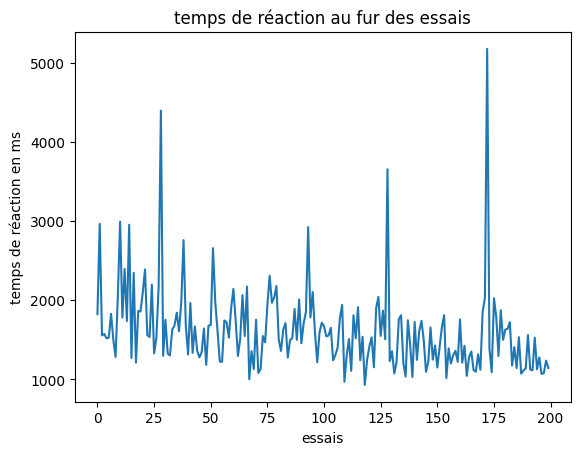

In [128]:
plt.plot(df_filtered["trial_rt"])
plt.title("temps de réaction au fur des essais")
plt.xlabel("essais")
plt.ylabel("temps de réaction en ms")
plt.show()

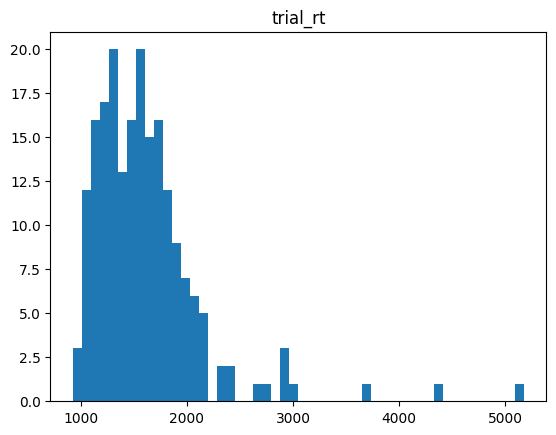

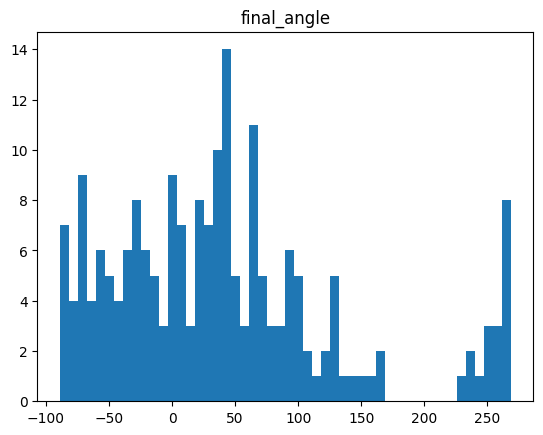

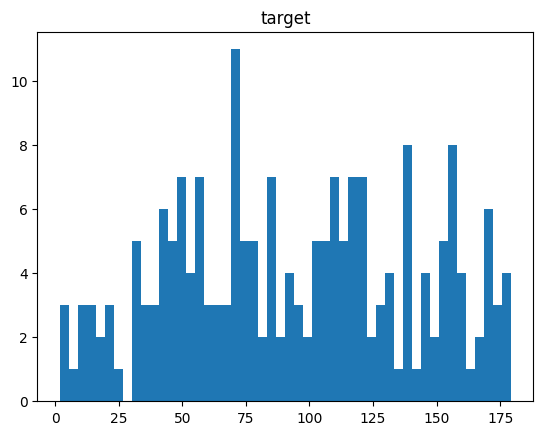

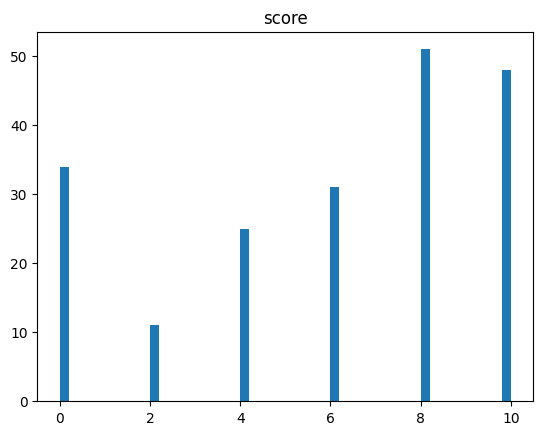

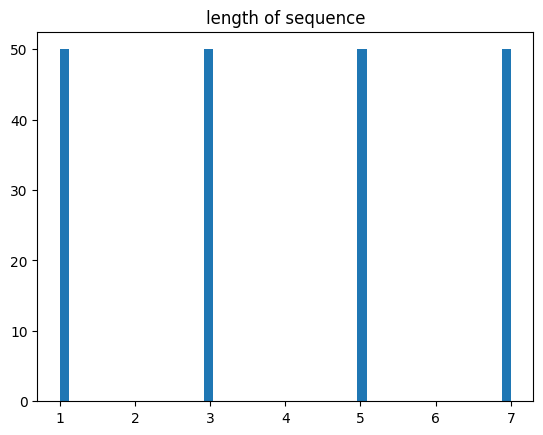

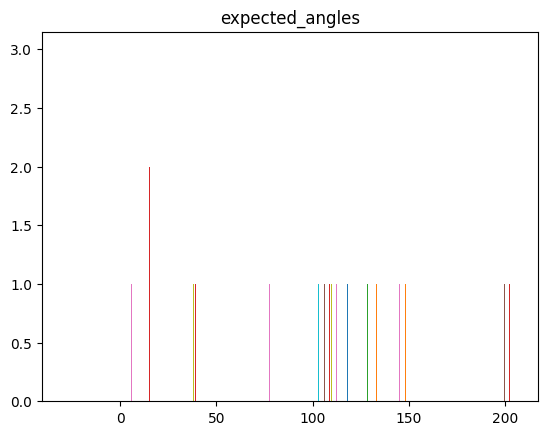

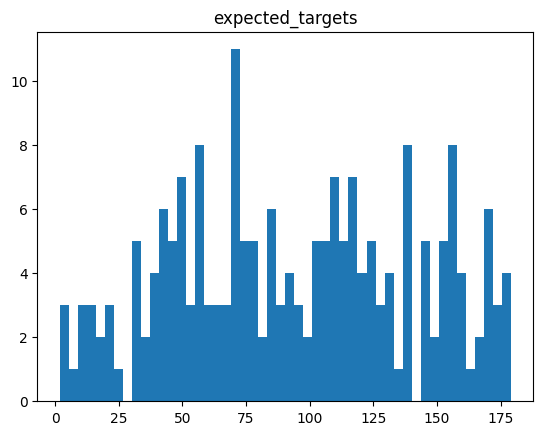

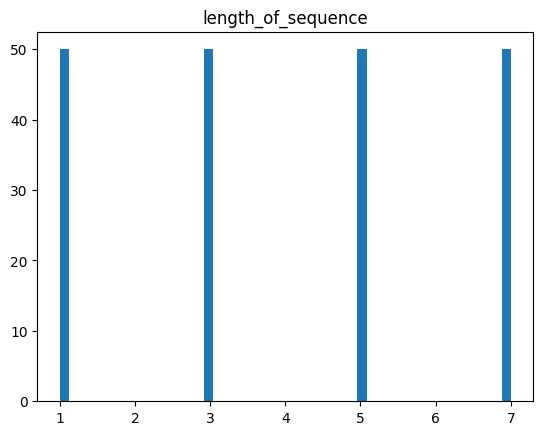

In [129]:
for column in df_filtered.columns:
    if column not in ["presented_angles", "stimulus_rotations"]:
        plt.figure()
        plt.hist(df_filtered[column], bins=50)
        plt.title(column)
        plt.show()

### data sur tous les participants

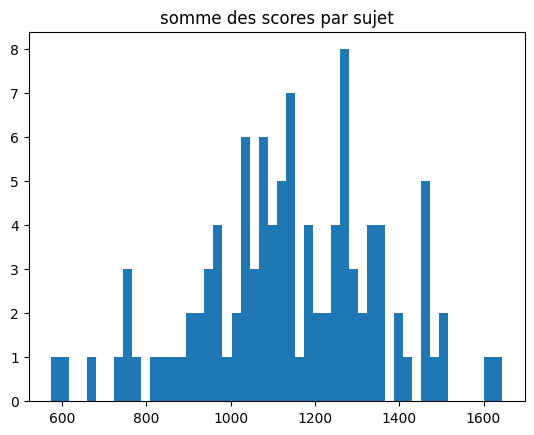

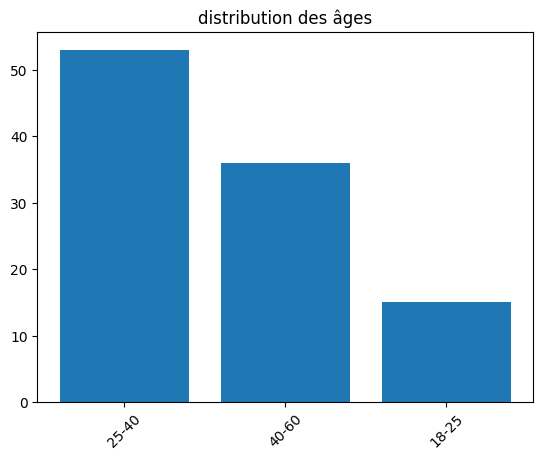

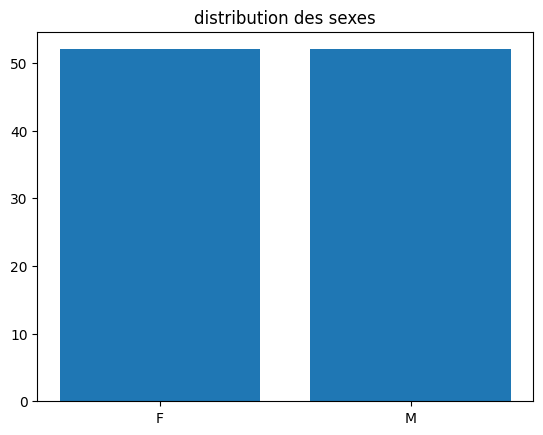

In [130]:
filepaths = glob.glob("données/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]

def data_sujets (dfs) : 
    score_sum = []
    age_tot = []
    sexe_tot = []
    for df in dfs :    
        survey = df[df["trial_type"] == "survey-dropdown"]
        if len(survey) == 0:
            age, sexe = None, None
        else:
            resp = json.loads(survey.iloc[0]["responses"])
            age = resp.get("0")
            sexe = resp.get("1")        
        age_tot.append(age)
        sexe_tot.append(sexe)
        
        df_filtered = df[df["stimulus_rotations"].notna()].copy()
        df_filtered = df_filtered.dropna(subset=["final_angle"]).copy()
        
        df_filtered['score'] = pd.to_numeric(df_filtered["score"], errors="coerce")
        score_sum.append(df_filtered["score"].sum(skipna=True))
        
    return score_sum, age_tot, sexe_tot

scores, ages, sexes = data_sujets(dfs)

plt.hist(scores, bins=50)
plt.title("somme des scores par sujet")
plt.show()

age_counts = pd.Series(ages).value_counts(dropna=False)
plt.bar(age_counts.index.astype(str), age_counts.values)
plt.xticks(rotation=45)
plt.title("distribution des âges")
plt.show()

sex_counts = pd.Series(sexes).value_counts(dropna=False)
plt.bar(sex_counts.index.astype(str), sex_counts.values)
plt.title("distribution des sexes")
plt.show()

In [131]:
print("il y a",sexes.count('F'), "femmes"), print("il y a",sexes.count('M'), 'hommes'), print("il y a",ages.count('18-25'), "personnes qui ont entre 18 et 25 ans"),
print("il y a",ages.count('25-40'), 'personnes qui ont entre 25 et 40 ans'), print("il y a",ages.count('40-60'), 'personnes qui ont entre 40 et 60 ans')

il y a 52 femmes
il y a 52 hommes
il y a 15 personnes qui ont entre 18 et 25 ans
il y a 53 personnes qui ont entre 25 et 40 ans
il y a 36 personnes qui ont entre 40 et 60 ans


(None, None)

### Disposition des angles sur un cercle

ici je dois changer en mettant le cercle de -90° à 90°
ca c'est bizarre


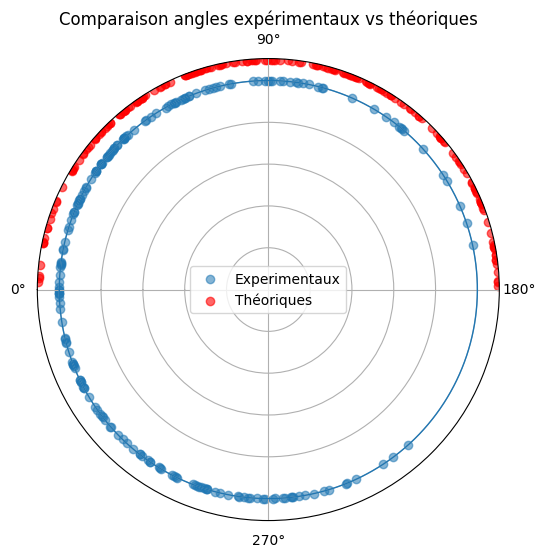

In [132]:
fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

ax.set_theta_zero_location("W")   # 0° à gauche (comme ton choix)
ax.set_theta_direction(-1)        # sens horaire

# ---- CERCLE TRIGONOMÉTRIQUE ----
theta = np.linspace(0, 2*np.pi, 400)
ax.plot(theta, np.ones_like(theta), linewidth=1)  # cercle unité

# labels angulaires
ax.set_thetagrids(
    angles=[0, 90, 180, 270],
    labels=["0°", "90°", "180°", "270°"]
)

# ---- TES DONNÉES ----
theta_presented = df_radian['final_angle'].values
theta_targets = df_radian['target'].values

ax.scatter(theta_presented, np.ones_like(theta_presented),
           alpha=0.55, label="Experimentaux")

ax.scatter(theta_targets, np.ones_like(theta_targets)*1.1,
           color='red', alpha=0.6, label="Théoriques")

ax.set_yticklabels([])   # enlève les labels du rayon
ax.set_title("Comparaison angles expérimentaux vs théoriques")
ax.legend()

plt.show()

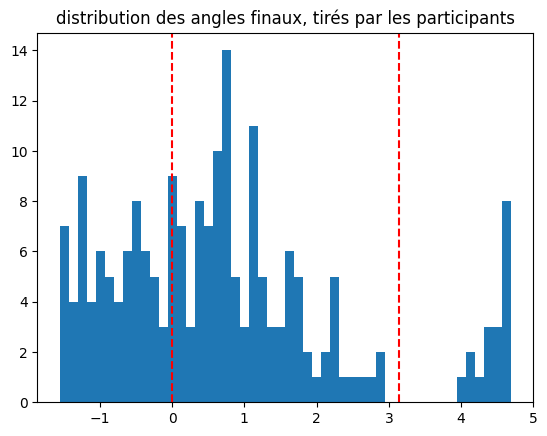

In [133]:
plt.hist(df_radian["final_angle"], bins=50)
plt.axvline(0, color='red', linestyle='--')
plt.axvline(np.pi, color='red', linestyle='--')
plt.title("distribution des angles finaux, tirés par les participants")
plt.show()

## Performances

### Est ce que les participants ont bien répondu ? (erreur entre angle tiré et la target) 

+ ajouter la confiance pour voir la distribution de la confiance pour les angles expected 

In [134]:
df_radian["error_to_target"] = circular_error(df_radian["final_angle"], df_radian["expected_targets"]) # erreur par rapport à l'angle théorique
df_filtered["error_to_target"] = circular_error_deg(df_filtered["final_angle"], df_filtered["expected_targets"]) # erreur par rapport à l'angle théorique

In [135]:
df_radian

,trial_rt,score,length of sequence,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected,error_to_target
0,1823.0,0,5,1.179913,1.778880,1.779308,"[-0.7853981633974483, 0.7853981633974483, 0.78...","[2.229669318992872, 1.0815990770306245, 1.1411...","[1.4442711555954237, 1.8669972404280728, 1.926...",-1.364073,-0.599395
1,2963.0,4,7,1.588910,1.213560,1.216674,"[0.7853981633974483, 0.0, -0.7853981633974483,...","[0.07640419676985905, 1.418391784669657, 1.505...","[0.8618023601673073, 1.418391784669657, 0.7203...",1.202601,0.372236
2,1554.0,4,3,0.286621,0.655773,0.655718,"[-0.7853981633974483, 0.0, -0.7853981633974483]","[1.3304683197284082, 0.704894341566264, 1.5025...","[0.54507015633096, 0.704894341566264, 0.717188...",0.655943,-0.369096
3,1573.0,0,5,2.259223,1.715086,1.722714,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.45141820558867524, 1.59234951861626, 1.3224...","[1.2368163689861236, 2.3777476820137085, 1.322...",-1.461586,0.536510
4,1519.0,8,3,1.640336,1.826013,1.825288,"[0.7853981633974483, -0.7853981633974483, 0.78...","[0.7710583307032722, 2.6990931943336176, 1.220...","[1.5564564941007206, 1.913695030936169, 2.0057...",-1.313276,-0.184952
...,...,...,...,...,...,...,...,...,...,...,...
195,1277.0,8,1,0.602677,0.794253,0.794253,[0.0],[0.7942534667707823],[0.7942534667707823],0.794253,-0.191577
196,1067.0,8,5,-0.017180,3.012161,3.012111,"[0.0, 0.7853981633974483, 0.7853981633974483, ...","[2.8867055744208034, 2.2819466552618737, 2.130...","[2.8867055744208034, 3.067344818659322, 2.9159...",-0.129279,0.112301
197,1079.0,8,5,-1.033971,1.923666,1.927946,"[0.7853981633974483, -0.7853981633974483, -0.7...","[1.5165459122352993, 2.2060316591877416, 2.349...","[2.3019440756327474, 1.420633495790293, 1.5640...",-1.235431,0.179675
198,1236.0,6,5,-0.491418,2.933196,2.934097,"[-0.7853981633974483, 0.7853981633974483, 0.0,...","[4.124233073710873, 1.9931780772216319, 3.1705...","[3.338834910313425, 2.7785762406190804, 3.1705...",-0.211451,-0.283923


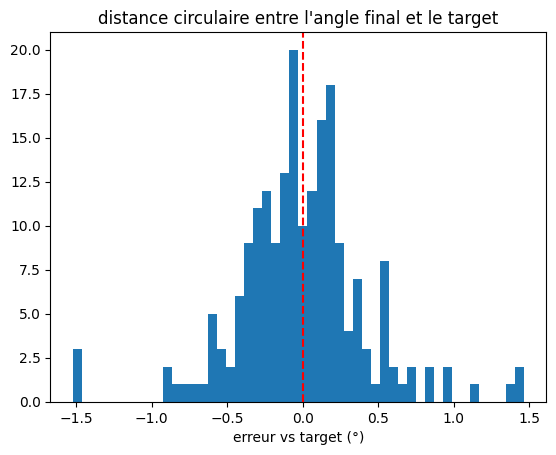

In [136]:
plt.hist(df_radian["error_to_target"], bins=50)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("erreur vs target (°)")
plt.title("distance circulaire entre l'angle final et le target")
plt.show()

### Est ce que les participants ignorent les rotations ? (ne considèrent que les gris)

j'ai besoin de prendre toutes les presented angles, et de garder seulement les 0°, et de comparer leur moyenne circulaire avec l'angle final tiré


In [137]:
df_radian["dict_angle_to_rotation"]= df_radian.apply(lambda row: dict(zip(row["presented_angles"], row["stimulus_rotations"])), axis=1) 
df_radian

,trial_rt,score,length of sequence,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected,error_to_target,dict_angle_to_rotation
0,1823.0,0,5,1.179913,1.778880,1.779308,"[-0.7853981633974483, 0.7853981633974483, 0.78...","[2.229669318992872, 1.0815990770306245, 1.1411...","[1.4442711555954237, 1.8669972404280728, 1.926...",-1.364073,-0.599395,"{2.229669318992872: -0.7853981633974483, 1.081..."
1,2963.0,4,7,1.588910,1.213560,1.216674,"[0.7853981633974483, 0.0, -0.7853981633974483,...","[0.07640419676985905, 1.418391784669657, 1.505...","[0.8618023601673073, 1.418391784669657, 0.7203...",1.202601,0.372236,"{0.07640419676985905: 0.7853981633974483, 1.41..."
2,1554.0,4,3,0.286621,0.655773,0.655718,"[-0.7853981633974483, 0.0, -0.7853981633974483]","[1.3304683197284082, 0.704894341566264, 1.5025...","[0.54507015633096, 0.704894341566264, 0.717188...",0.655943,-0.369096,"{1.3304683197284082: -0.7853981633974483, 0.70..."
3,1573.0,0,5,2.259223,1.715086,1.722714,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.45141820558867524, 1.59234951861626, 1.3224...","[1.2368163689861236, 2.3777476820137085, 1.322...",-1.461586,0.536510,"{0.45141820558867524: 0.7853981633974483, 1.59..."
4,1519.0,8,3,1.640336,1.826013,1.825288,"[0.7853981633974483, -0.7853981633974483, 0.78...","[0.7710583307032722, 2.6990931943336176, 1.220...","[1.5564564941007206, 1.913695030936169, 2.0057...",-1.313276,-0.184952,"{0.7710583307032722: 0.7853981633974483, 2.699..."
...,...,...,...,...,...,...,...,...,...,...,...,...
195,1277.0,8,1,0.602677,0.794253,0.794253,[0.0],[0.7942534667707823],[0.7942534667707823],0.794253,-0.191577,{0.7942534667707823: 0.0}
196,1067.0,8,5,-0.017180,3.012161,3.012111,"[0.0, 0.7853981633974483, 0.7853981633974483, ...","[2.8867055744208034, 2.2819466552618737, 2.130...","[2.8867055744208034, 3.067344818659322, 2.9159...",-0.129279,0.112301,"{2.8867055744208034: 0.0, 2.2819466552618737: ..."
197,1079.0,8,5,-1.033971,1.923666,1.927946,"[0.7853981633974483, -0.7853981633974483, -0.7...","[1.5165459122352993, 2.2060316591877416, 2.349...","[2.3019440756327474, 1.420633495790293, 1.5640...",-1.235431,0.179675,"{1.5165459122352993: 0.7853981633974483, 2.206..."
198,1236.0,6,5,-0.491418,2.933196,2.934097,"[-0.7853981633974483, 0.7853981633974483, 0.0,...","[4.124233073710873, 1.9931780772216319, 3.1705...","[3.338834910313425, 2.7785762406190804, 3.1705...",-0.211451,-0.283923,"{4.124233073710873: -0.7853981633974483, 1.993..."


In [138]:
df_radian["angles_sans_rotation"]= df_radian["dict_angle_to_rotation"].apply(lambda d: [angle for angle, rot in d.items() if np.isclose(rot, 0)])

df_radian_error_wo_rotation = df_radian[df_radian["angles_sans_rotation"].apply(len)>0]

df_radian_error_wo_rotation["error_sola_gris"] = circular_error(df_radian_error_wo_rotation["final_angle"], df_radian_error_wo_rotation["angles_sans_rotation"].apply(Angle_moyen_circulaire))
df_radian_error_wo_rotation

/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_13003/2690521830.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_radian_error_wo_rotation["error_sola_gris"] = circular_error(df_radian_error_wo_rotation["final_angle"], df_radian_error_wo_rotation["angles_sans_rotation"].apply(Angle_moyen_circulaire))


,trial_rt,score,length of sequence,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected,error_to_target,dict_angle_to_rotation,angles_sans_rotation,error_sola_gris
1,2963.0,4,7,1.588910,1.213560,1.216674,"[0.7853981633974483, 0.0, -0.7853981633974483,...","[0.07640419676985905, 1.418391784669657, 1.505...","[0.8618023601673073, 1.418391784669657, 0.7203...",1.202601,0.372236,"{0.07640419676985905: 0.7853981633974483, 1.41...","[1.418391784669657, 1.499353755186889, 1.15683...",0.955173
2,1554.0,4,3,0.286621,0.655773,0.655718,"[-0.7853981633974483, 0.0, -0.7853981633974483]","[1.3304683197284082, 0.704894341566264, 1.5025...","[0.54507015633096, 0.704894341566264, 0.717188...",0.655943,-0.369096,"{1.3304683197284082: -0.7853981633974483, 0.70...",[0.704894341566264],-0.065826
3,1573.0,0,5,2.259223,1.715086,1.722714,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.45141820558867524, 1.59234951861626, 1.3224...","[1.2368163689861236, 2.3777476820137085, 1.322...",-1.461586,0.536510,"{0.45141820558867524: 0.7853981633974483, 1.59...","[1.322460781337291, 2.224567520771709, 1.45197...",1.429701
5,1526.0,4,3,1.739785,2.083662,2.084139,"[0.7853981633974483, 0.0, 0.0]","[1.071357278781488, 2.356877433589442, 2.03878...","[1.8567554421789363, 2.356877433589442, 2.0387...",-1.059457,-0.344354,"{1.071357278781488: 0.7853981633974483, 2.3568...","[2.356877433589442, 2.038783726011232]",0.640870
6,1827.0,8,1,2.401147,2.528916,2.528916,[0.0],[2.528915633377776],[2.528915633377776],-0.612677,-0.127769,{2.528915633377776: 0.0},[2.528915633377776],1.136689
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,1277.0,8,1,0.602677,0.794253,0.794253,[0.0],[0.7942534667707823],[0.7942534667707823],0.794253,-0.191577,{0.7942534667707823: 0.0},[0.7942534667707823],0.205550
196,1067.0,8,5,-0.017180,3.012161,3.012111,"[0.0, 0.7853981633974483, 0.7853981633974483, ...","[2.8867055744208034, 2.2819466552618737, 2.130...","[2.8867055744208034, 3.067344818659322, 2.9159...",-0.129279,0.112301,"{2.8867055744208034: 0.0, 2.2819466552618737: ...","[2.8867055744208034, 3.1039039483177593]",-1.514833
197,1079.0,8,5,-1.033971,1.923666,1.927946,"[0.7853981633974483, -0.7853981633974483, -0.7...","[1.5165459122352993, 2.2060316591877416, 2.349...","[2.3019440756327474, 1.420633495790293, 1.5640...",-1.235431,0.179675,"{1.5165459122352993: 0.7853981633974483, 2.206...",[2.55670260956398],0.829270
198,1236.0,6,5,-0.491418,2.933196,2.934097,"[-0.7853981633974483, 0.7853981633974483, 0.0,...","[4.124233073710873, 1.9931780772216319, 3.1705...","[3.338834910313425, 2.7785762406190804, 3.1705...",-0.211451,-0.283923,"{4.124233073710873: -0.7853981633974483, 1.993...","[3.1705555288923466, 2.5715651955997556]",1.214644


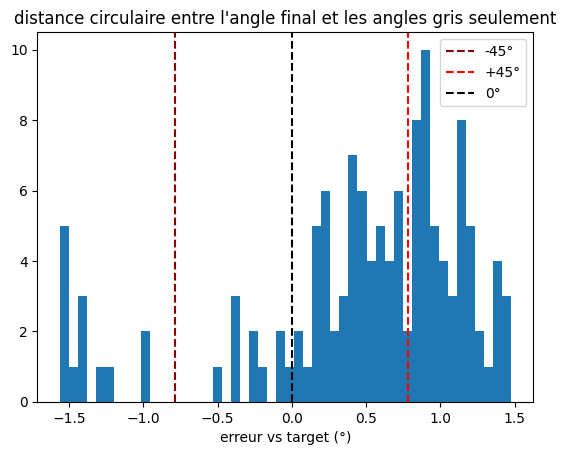

In [139]:
plt.hist(df_radian_error_wo_rotation["error_sola_gris"], bins=50)
plt.axvline(np.deg2rad(-45), color='darkred', linestyle='--', label="-45°") 
plt.axvline(np.deg2rad(45), color='red', linestyle='--', label="+45°") 
plt.axvline(np.deg2rad(0), color='black', linestyle='--', label="0°") 

plt.xlabel("erreur vs target (°)")
plt.title("distance circulaire entre l'angle final et les angles gris seulement")
plt.legend()
plt.show()

### Est ce que les participants ignorent les rotations ? (ne prennent pas en compte les couleurs, seulement les orientations qu'ils voient)

In [140]:
df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(Angle_moyen_circulaire)
df_radian["error_wo_rotation"] = circular_error(df_radian["final_angle"], df_radian["expected_angles_wo_rot"])  
df_radian

,trial_rt,score,length of sequence,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected,error_to_target,dict_angle_to_rotation,angles_sans_rotation,expected_angles_wo_rot,error_wo_rotation
0,1823.0,0,5,1.179913,1.778880,1.779308,"[-0.7853981633974483, 0.7853981633974483, 0.78...","[2.229669318992872, 1.0815990770306245, 1.1411...","[1.4442711555954237, 1.8669972404280728, 1.926...",-1.364073,-0.599395,"{2.229669318992872: -0.7853981633974483, 1.081...",[],1.216895,-0.036982
1,2963.0,4,7,1.588910,1.213560,1.216674,"[0.7853981633974483, 0.0, -0.7853981633974483,...","[0.07640419676985905, 1.418391784669657, 1.505...","[0.8618023601673073, 1.418391784669657, 0.7203...",1.202601,0.372236,"{0.07640419676985905: 0.7853981633974483, 1.41...","[1.418391784669657, 1.499353755186889, 1.15683...",1.205989,0.382922
2,1554.0,4,3,0.286621,0.655773,0.655718,"[-0.7853981633974483, 0.0, -0.7853981633974483]","[1.3304683197284082, 0.704894341566264, 1.5025...","[0.54507015633096, 0.704894341566264, 0.717188...",0.655943,-0.369096,"{1.3304683197284082: -0.7853981633974483, 0.70...",[0.704894341566264],1.198021,-0.911399
3,1573.0,0,5,2.259223,1.715086,1.722714,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.45141820558867524, 1.59234951861626, 1.3224...","[1.2368163689861236, 2.3777476820137085, 1.322...",-1.461586,0.536510,"{0.45141820558867524: 0.7853981633974483, 1.59...","[1.322460781337291, 2.224567520771709, 1.45197...",1.473999,0.785225
4,1519.0,8,3,1.640336,1.826013,1.825288,"[0.7853981633974483, -0.7853981633974483, 0.78...","[0.7710583307032722, 2.6990931943336176, 1.220...","[1.5564564941007206, 1.913695030936169, 2.0057...",-1.313276,-0.184952,"{0.7710583307032722: 0.7853981633974483, 2.699...",[],0.843855,0.796481
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,1277.0,8,1,0.602677,0.794253,0.794253,[0.0],[0.7942534667707823],[0.7942534667707823],0.794253,-0.191577,{0.7942534667707823: 0.0},[0.7942534667707823],0.794253,-0.191577
196,1067.0,8,5,-0.017180,3.012161,3.012111,"[0.0, 0.7853981633974483, 0.7853981633974483, ...","[2.8867055744208034, 2.2819466552618737, 2.130...","[2.8867055744208034, 3.067344818659322, 2.9159...",-0.129279,0.112301,"{2.8867055744208034: 0.0, 2.2819466552618737: ...","[2.8867055744208034, 3.1039039483177593]",-0.403664,0.386484
197,1079.0,8,5,-1.033971,1.923666,1.927946,"[0.7853981633974483, -0.7853981633974483, -0.7...","[1.5165459122352993, 2.2060316591877416, 2.349...","[2.3019440756327474, 1.420633495790293, 1.5640...",-1.235431,0.179675,"{1.5165459122352993: 0.7853981633974483, 2.206...",[2.55670260956398],-0.850073,-0.183899
198,1236.0,6,5,-0.491418,2.933196,2.934097,"[-0.7853981633974483, 0.7853981633974483, 0.0,...","[4.124233073710873, 1.9931780772216319, 3.1705...","[3.338834910313425, 2.7785762406190804, 3.1705...",-0.211451,-0.283923,"{4.124233073710873: -0.7853981633974483, 1.993...","[3.1705555288923466, 2.5715651955997556]",0.057712,-0.549131


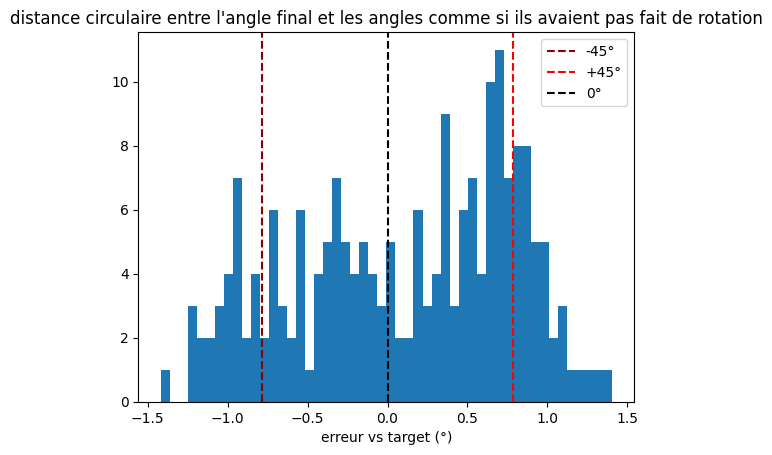

In [141]:
plt.hist(df_radian["error_wo_rotation"], bins=50)
plt.axvline(np.deg2rad(-45), color='darkred', linestyle='--', label="-45°") 
plt.axvline(np.deg2rad(45), color='red', linestyle='--', label="+45°") 
plt.axvline(np.deg2rad(0), color='black', linestyle='--', label="0°") 

plt.xlabel("erreur vs target (°)")
plt.title("distance circulaire entre l'angle final et les angles comme si ils avaient pas fait de rotation")
plt.legend()
plt.show()

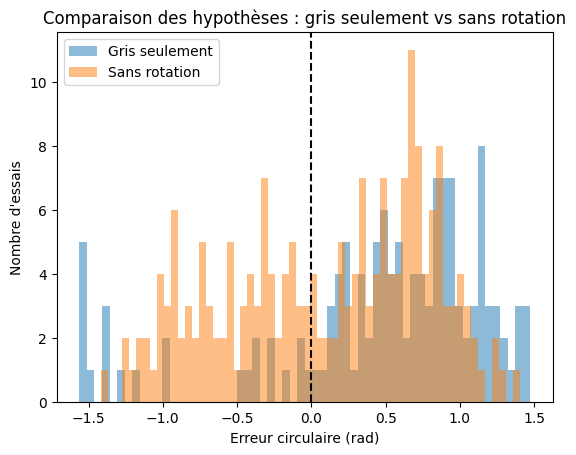

In [142]:
plt.hist(df_radian_error_wo_rotation["error_sola_gris"], 
         bins=60, alpha=0.5, label="Gris seulement")

plt.hist(df_radian["error_wo_rotation"], 
         bins=60, alpha=0.5, label="Sans rotation")

plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Erreur circulaire (rad)")
plt.ylabel("Nombre d'essais")
plt.title("Comparaison des hypothèses : gris seulement vs sans rotation")
plt.legend()
plt.show()

### rotation moyenne vs erreur

In [169]:
df_radian

,trial_rt,score,length of sequence,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected,error_to_target,dict_angle_to_rotation,angles_sans_rotation,expected_angles_wo_rot,error_wo_rotation,mean_rotation
0,1823.0,0,5,1.179913,1.778880,1.779308,"[-0.7853981633974483, 0.7853981633974483, 0.78...","[2.229669318992872, 1.0815990770306245, 1.1411...","[1.4442711555954237, 1.8669972404280728, 1.926...",-1.364073,-0.599395,"{2.229669318992872: -0.7853981633974483, 1.081...",[],1.216895,-0.036982,0.471239
1,2963.0,4,7,1.588910,1.213560,1.216674,"[0.7853981633974483, 0.0, -0.7853981633974483,...","[0.07640419676985905, 1.418391784669657, 1.505...","[0.8618023601673073, 1.418391784669657, 0.7203...",1.202601,0.372236,"{0.07640419676985905: 0.7853981633974483, 1.41...","[1.418391784669657, 1.499353755186889, 1.15683...",1.205989,0.382922,0.112200
2,1554.0,4,3,0.286621,0.655773,0.655718,"[-0.7853981633974483, 0.0, -0.7853981633974483]","[1.3304683197284082, 0.704894341566264, 1.5025...","[0.54507015633096, 0.704894341566264, 0.717188...",0.655943,-0.369096,"{1.3304683197284082: -0.7853981633974483, 0.70...",[0.704894341566264],1.198021,-0.911399,-0.523599
3,1573.0,0,5,2.259223,1.715086,1.722714,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.45141820558867524, 1.59234951861626, 1.3224...","[1.2368163689861236, 2.3777476820137085, 1.322...",-1.461586,0.536510,"{0.45141820558867524: 0.7853981633974483, 1.59...","[1.322460781337291, 2.224567520771709, 1.45197...",1.473999,0.785225,0.314159
4,1519.0,8,3,1.640336,1.826013,1.825288,"[0.7853981633974483, -0.7853981633974483, 0.78...","[0.7710583307032722, 2.6990931943336176, 1.220...","[1.5564564941007206, 1.913695030936169, 2.0057...",-1.313276,-0.184952,"{0.7710583307032722: 0.7853981633974483, 2.699...",[],0.843855,0.796481,0.261799
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,1277.0,8,1,0.602677,0.794253,0.794253,[0.0],[0.7942534667707823],[0.7942534667707823],0.794253,-0.191577,{0.7942534667707823: 0.0},[0.7942534667707823],0.794253,-0.191577,0.000000
196,1067.0,8,5,-0.017180,3.012161,3.012111,"[0.0, 0.7853981633974483, 0.7853981633974483, ...","[2.8867055744208034, 2.2819466552618737, 2.130...","[2.8867055744208034, 3.067344818659322, 2.9159...",-0.129279,0.112301,"{2.8867055744208034: 0.0, 2.2819466552618737: ...","[2.8867055744208034, 3.1039039483177593]",-0.403664,0.386484,0.157080
197,1079.0,8,5,-1.033971,1.923666,1.927946,"[0.7853981633974483, -0.7853981633974483, -0.7...","[1.5165459122352993, 2.2060316591877416, 2.349...","[2.3019440756327474, 1.420633495790293, 1.5640...",-1.235431,0.179675,"{1.5165459122352993: 0.7853981633974483, 2.206...",[2.55670260956398],-0.850073,-0.183899,-0.314159
198,1236.0,6,5,-0.491418,2.933196,2.934097,"[-0.7853981633974483, 0.7853981633974483, 0.0,...","[4.124233073710873, 1.9931780772216319, 3.1705...","[3.338834910313425, 2.7785762406190804, 3.1705...",-0.211451,-0.283923,"{4.124233073710873: -0.7853981633974483, 1.993...","[3.1705555288923466, 2.5715651955997556]",0.057712,-0.549131,-0.157080


In [168]:
df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(np.mean)

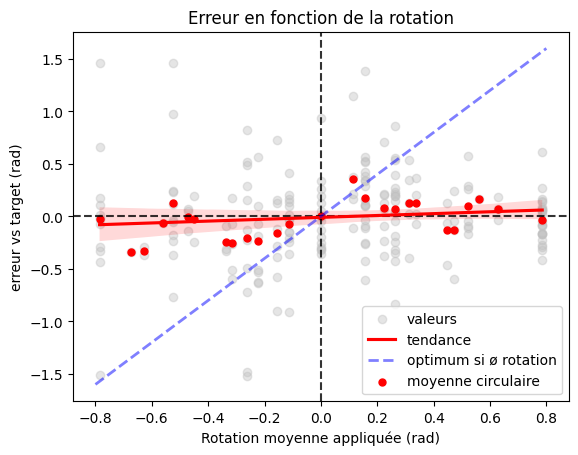

In [175]:
x = (df_radian.groupby("mean_rotation")["error_to_target"].apply(np.mean).reset_index().sort_values("mean_rotation"))

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

sns.regplot(x="mean_rotation", y="error_to_target", data=df_radian, color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
plt.plot(np.linspace(-0.8,0.8,100),(np.linspace(-1.6,1.6,100)),"--" , color = "blue",label= "optimum si ø rotation", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_to_target"], color="red", s=25, label="moyenne circulaire")

plt.xlabel("Rotation moyenne appliquée (rad)")
plt.ylabel("erreur vs target (rad)")
plt.title("Erreur en fonction de la rotation")
plt.legend()
plt.show()

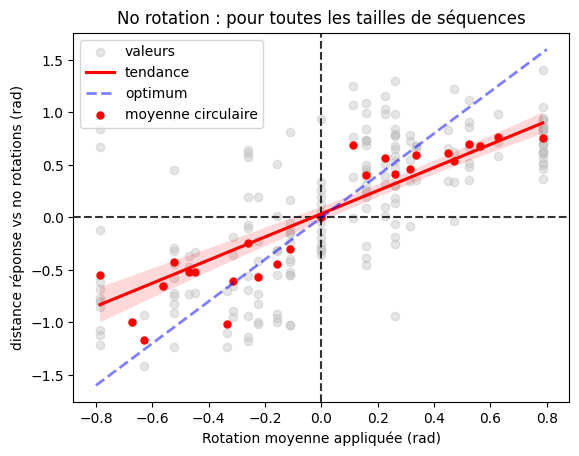

In [177]:
x = (df_radian.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))


plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df_radian, color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
plt.plot(np.linspace(-0.8,0.8,100),(np.linspace(-1.6,1.6,100)),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=25, label="moyenne circulaire")

plt.xlabel("Rotation moyenne appliquée (rad)")
plt.ylabel("distance réponse vs no rotations (rad)")
plt.title("No rotation : pour toutes les tailles de séquences")
plt.legend()
plt.show()

plot pour différentes tailles de séquences

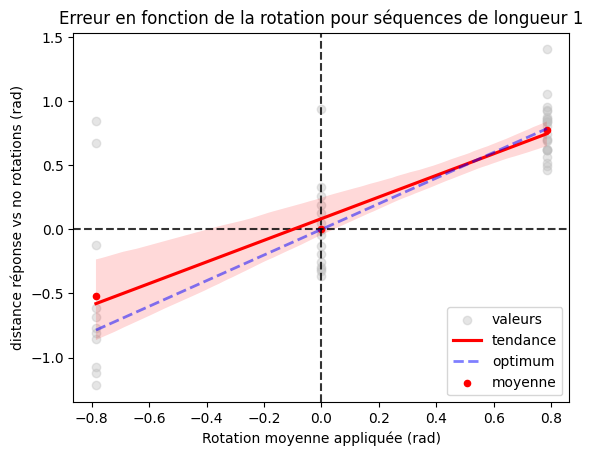

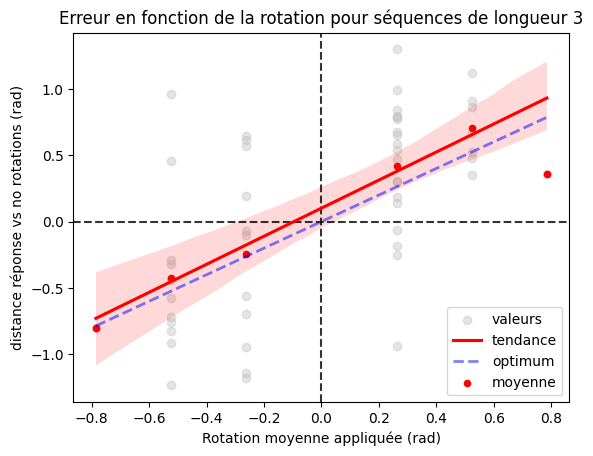

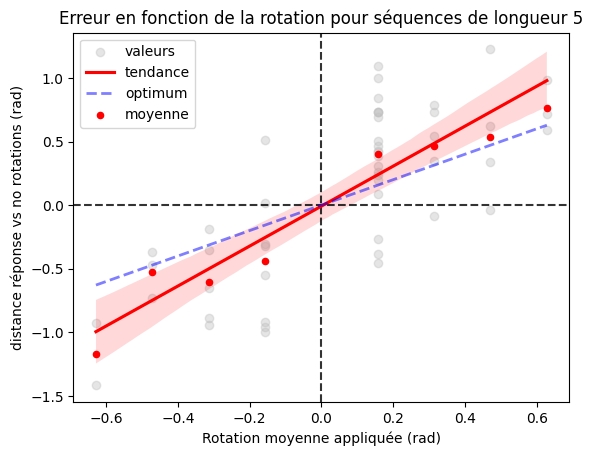

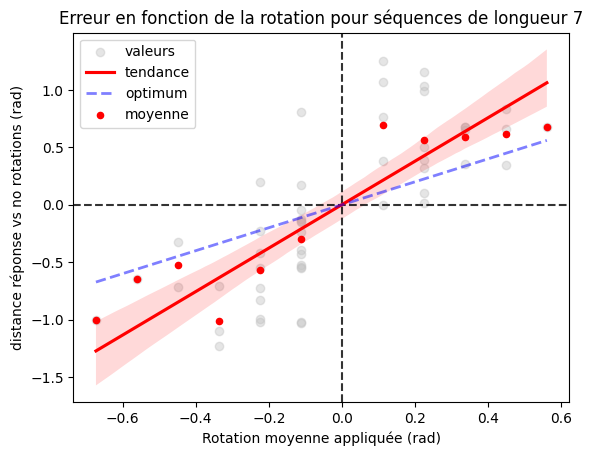

In [183]:
for seqlen in [1,3,5,7] :
    plt.figure()
    x = (df_radian[df_radian["length of sequence"]==seqlen].groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))

    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

    borne = x["mean_rotation"]
    sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df_radian[df_radian["length of sequence"]==seqlen], color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
    plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=20, label="moyenne")

    plt.xlabel("Rotation moyenne appliquée (rad)")
    plt.ylabel("distance réponse vs no rotations (rad)")
    plt.title(f"Erreur en fonction de la rotation pour séquences de longueur {seqlen}")
    plt.legend()
    plt.show()

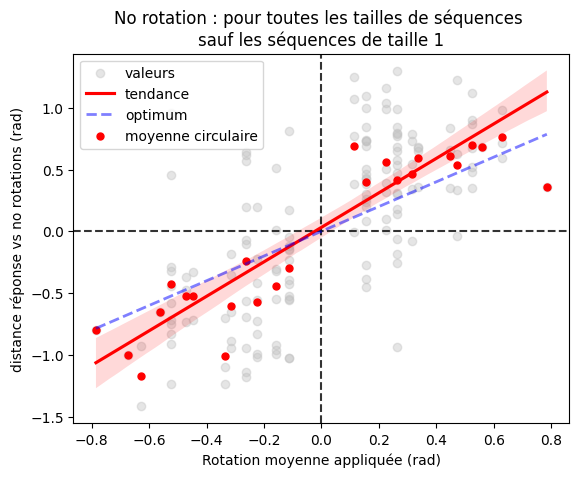

In [185]:
df = df_radian[df_radian["length of sequence"]!=1]

x = (df.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

borne = x["mean_rotation"]
sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df, color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=25, label="moyenne circulaire")

plt.xlabel("Rotation moyenne appliquée (rad)")
plt.ylabel("distance réponse vs no rotations (rad)")
plt.title("No rotation : pour toutes les tailles de séquences \nsauf les séquences de taille 1")
plt.legend()
plt.show()

## Reaction time et confiance

### RT vs erreur

erreur entre l'angle tiré et la target en fonction du temps de réaction 

*on observe que l'erreur semble être corrélée au temps de réaction, ce qui suggère que les participants font moins d'erreur quand ils répondent plus rapidement*

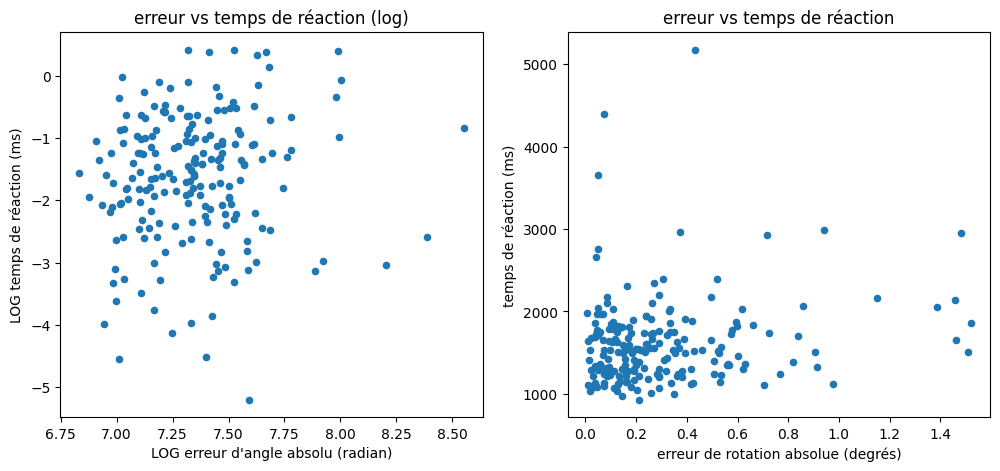

In [149]:
plt.subplots(1,2, figsize=(12,5))

plt.subplot(1,2,1) 
plt.scatter(df_radian["trial_rt"].apply(np.log), np.abs(df_radian["error_to_target"]).apply(np.log), s=20)
plt.xlabel("LOG erreur d'angle absolu (radian)")
plt.ylabel("LOG temps de réaction (ms)")
plt.title("erreur vs temps de réaction (log)")

plt.subplot(1,2,2) 
plt.scatter(np.abs(df_radian["error_to_target"]), df_radian["trial_rt"], s=20)
plt.xlabel("erreur de rotation absolue (degrés)")
plt.ylabel("temps de réaction (ms)")
plt.title("erreur vs temps de réaction")
plt.show()

erreur vs le temps

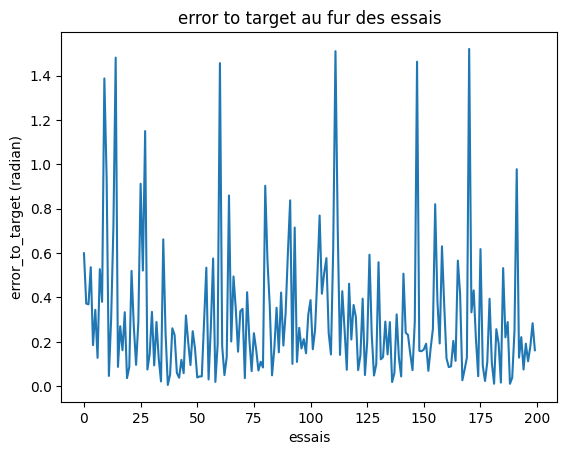

In [150]:
plt.plot(np.abs(df_radian["error_to_target"]))
plt.xlabel("essais")
plt.ylabel("error_to_target (radian)")
plt.title("error to target au fur des essais")
plt.show()

### RT vs temps

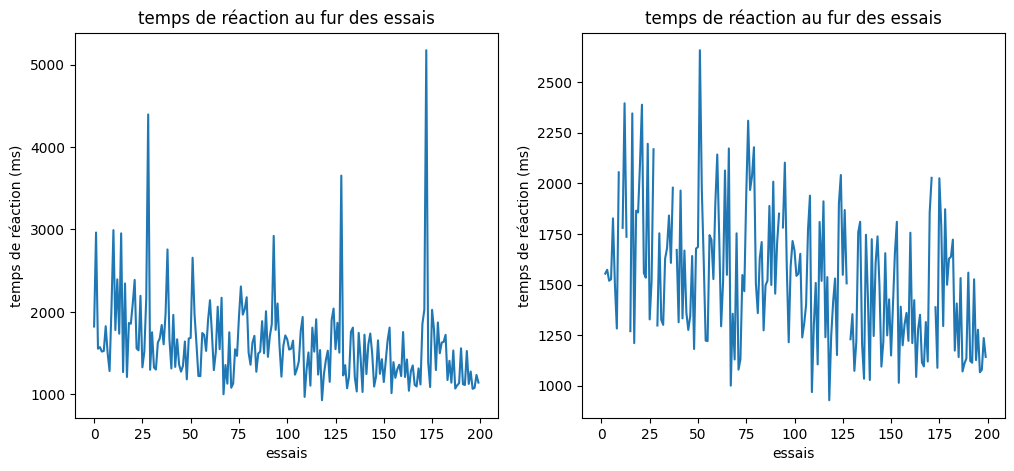

In [151]:
plt.subplots(1,2, figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(np.abs(df_radian["trial_rt"]))
plt.xlabel("essais")
plt.ylabel("temps de réaction (ms)")
plt.title("temps de réaction au fur des essais")

mean_rt = df_radian["trial_rt"].mean()
std_rt = df_radian["trial_rt"].std()
upper_threshold = mean_rt + 2*std_rt

rt_filtered = df_radian["trial_rt"].copy()
rt_filtered[(rt_filtered > upper_threshold)] = np.nan

plt.subplot(1,2,2)
plt.plot(rt_filtered)
plt.xlabel("essais")
plt.ylabel("temps de réaction (ms)")
plt.title("temps de réaction au fur des essais")
plt.show()

### RT vs seq length

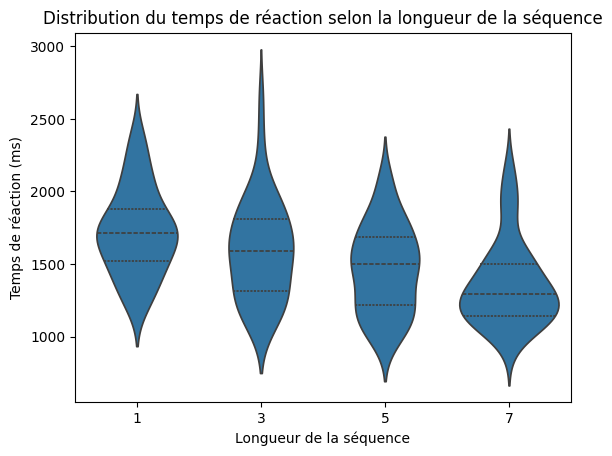

In [156]:
sns.violinplot(x="length of sequence", y=rt_filtered, data=df_radian, inner="quartile")

plt.xlabel("Longueur de la séquence")
plt.ylabel("Temps de réaction (ms)")
plt.title("Distribution du temps de réaction selon la longueur de la séquence")

plt.show()

### RT vs la confiance 

### RT vs score

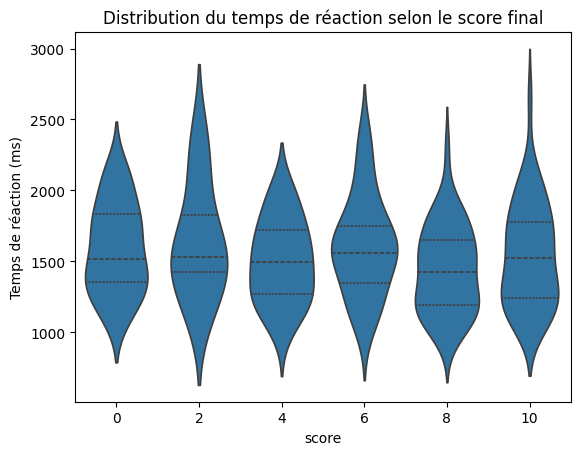

In [155]:
sns.violinplot(x="score", y=rt_filtered, data=df_radian, inner="quartile")

plt.xlabel("score")
plt.ylabel("Temps de réaction (ms)")
plt.title("Distribution du temps de réaction selon le score final")

plt.show()